# 01 · Intent classifier (Member 4: chatbot, model 1)

Fine-tunes **xlm-roberta-base** (pretrained on 100 languages including Sinhala) to sort a farmer's question into
one of 12 intents, and compares it with a **TF-IDF + logistic regression** baseline on the same splits.

- Data: `data/intents.csv` (train / val / test split by passage group, see notebook 00).
- Questions the model is not sure about are sent to `out_of_scope`: if the top probability is below a threshold.
  **The threshold is chosen on the validation split only**; the test split is used once, at the end.
- `RETRAIN = True` trains from scratch (fixed seeds) and saves the model to `../artifacts/intent/`.
  `RETRAIN = False` loads the saved model and only evaluates it (seconds).

In [1]:
RETRAIN = True
SEED = 20261018
MODEL_NAME = "xlm-roberta-base"
MAX_LEN, BATCH, LR, EPOCHS, PATIENCE, WARMUP, WEIGHT_DECAY = 64, 16, 3e-5, 8, 2, 0.1, 0.01

In [2]:
from pathlib import Path

HERE = Path.cwd()
DATA = HERE / "data"                                   # CSVs exported by member4_chatbot.pipeline.export_notebook_data
IN_REPO = (HERE.parent / "member4_chatbot").exists()   # False in Colab
ARTIFACTS = (HERE.parent / "artifacts") if IN_REPO else (HERE / "artifacts")
CHROMA = (HERE.parent / "data" / "chroma") if IN_REPO else (HERE / "chroma")
print("data:", DATA.resolve(), "| artifacts:", ARTIFACTS.resolve())

data: E:\soilmind\backend\member4-chatbot\notebooks\data | artifacts: E:\soilmind\backend\member4-chatbot\artifacts


In [3]:
import json, math, os, random, time, copy
import numpy as np
import pandas as pd
import torch
import joblib
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, precision_recall_fscore_support, confusion_matrix
from sklearn.pipeline import make_pipeline, make_union
from transformers import AutoModelForSequenceClassification, AutoTokenizer, get_linear_schedule_with_warmup, set_seed

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); set_seed(SEED)
torch.set_num_threads(os.cpu_count())
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
OUT = ARTIFACTS / "intent"
print("device:", DEVICE, "| torch", torch.__version__)

device: cpu | torch 2.14.1+cpu


In [4]:
df = pd.read_csv(DATA / "intents.csv", keep_default_na=False)
LABELS = sorted(df.intent.unique())
L2I = {l: i for i, l in enumerate(LABELS)}
OOS = L2I["out_of_scope"]
tr, va, te = (df[df.split == s].reset_index(drop=True) for s in ("train", "val", "test"))
y_tr, y_va, y_te = (d.intent.map(L2I).to_numpy() for d in (tr, va, te))
print({s: len(d) for s, d in zip(("train", "val", "test"), (tr, va, te))}, "|", len(LABELS), "intents")
df.pivot_table(index="intent", columns="split", values="id", aggfunc="count")

{'train': 1522, 'val': 380, 'test': 363} | 12 intents


split,test,train,val
intent,,,
crop_choice,63,293,61
crop_establishment,36,141,19
deficiency_symptom,17,82,17
fertilizer_amount,69,161,87
fertilizer_timing,19,85,16
greeting_help,16,73,16
liming_ph,17,78,21
my_field_status,19,89,21
out_of_scope,50,228,48


## Helpers: the confidence threshold and the metrics
A prediction becomes `out_of_scope` when the top probability is below the threshold τ. τ is picked on the
validation split by macro-F1 (grid 0.00 – 0.95; ties go to the smaller τ).

In [5]:
def apply_threshold(probs, tau):
    pred = probs.argmax(1).copy()
    pred[probs.max(1) < tau] = OOS
    return pred

def choose_threshold(probs, y):
    grid = np.round(np.arange(0.0, 0.951, 0.05), 2)
    scores = [f1_score(y, apply_threshold(probs, t), average="macro") for t in grid]
    best = int(np.argmax(scores))
    return float(grid[best]), scores

def oos_pr(y, pred):
    p, r, f, _ = precision_recall_fscore_support(y == OOS, pred == OOS, average="binary", zero_division=0)
    return {"oos_precision": round(float(p), 4), "oos_recall": round(float(r), 4), "oos_f1": round(float(f), 4)}

def evaluate(frame, y, pred):
    out = {}
    for name, mask in [("all", np.ones(len(frame), bool)), ("en", (frame.lang == "en").to_numpy()),
                       ("si", (frame.lang == "si").to_numpy()), ("si_latn", (frame.lang == "si_latn").to_numpy())]:
        if mask.sum() == 0:
            continue
        yt, yp = y[mask], pred[mask]
        present = sorted(set(yt))
        out[name] = {"n": int(mask.sum()), "accuracy": round(accuracy_score(yt, yp), 4),
                     "macro_f1": round(f1_score(yt, yp, labels=present, average="macro", zero_division=0), 4), **oos_pr(yt, yp)}
        if name in ("en", "si"):
            f = f1_score(yt, yp, labels=present, average=None, zero_division=0)
            out[name]["per_intent_f1"] = {LABELS[l]: round(float(v), 4) for l, v in zip(present, f)}
    return out

## Baseline: TF-IDF + logistic regression
Word 1–2-grams plus character 2–5-grams (character n-grams cope with Sinhala spelling variants and Singlish).
The regularisation C is chosen on validation macro-F1.

In [6]:
TOKEN = r"[^\s.,;:!?()\[\]\"'/|]+"   # \w would split Sinhala words at vowel signs

def make_baseline(C):
    return make_pipeline(
        make_union(TfidfVectorizer(analyzer="word", token_pattern=TOKEN, ngram_range=(1, 2), sublinear_tf=True),
                   TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), sublinear_tf=True, min_df=2)),
        LogisticRegression(C=C, max_iter=5000, class_weight="balanced"))

if RETRAIN:
    t0 = time.time()
    val_f1 = {}
    for C in (1, 3, 10, 30, 100):
        m = make_baseline(C).fit(tr.text, y_tr)
        val_f1[C] = f1_score(y_va, m.predict(va.text), average="macro")
    BEST_C = max(val_f1, key=val_f1.get)
    baseline = make_baseline(BEST_C).fit(tr.text, y_tr)
    print("validation macro-F1 by C:", {c: round(v, 4) for c, v in val_f1.items()}, "-> C =", BEST_C, f"({time.time() - t0:.0f} s)")
else:
    baseline = joblib.load(OUT / "baseline_tfidf_logreg.joblib")
    BEST_C = baseline.steps[-1][1].C
bl_va, bl_te = baseline.predict_proba(va.text), baseline.predict_proba(te.text)
BL_TAU, _ = choose_threshold(bl_va, y_va)
print("baseline threshold (chosen on validation):", BL_TAU)

validation macro-F1 by C: {1: 0.7555, 3: 0.7546, 10: 0.7642, 30: 0.7653, 100: 0.7641} -> C = 30 (6 s)
baseline threshold (chosen on validation): 0.35


## XLM-RoBERTa fine-tuning
A plain PyTorch loop: AdamW, linear warm-up and decay, gradient clipping. After every epoch the validation
macro-F1 is measured; the best epoch's weights are kept, and training stops after 2 epochs without improvement.

In [7]:
tok = AutoTokenizer.from_pretrained(MODEL_NAME if RETRAIN else OUT / "model")

def batches(texts, size):
    for i in range(0, len(texts), size):
        yield tok(list(texts[i:i + size]), truncation=True, max_length=MAX_LEN, padding=True, return_tensors="pt")

@torch.inference_mode()
def predict_proba(model, texts, size=64):
    model.eval()
    out = [torch.softmax(model(**{k: v.to(model.device) for k, v in enc.items()}).logits, -1).cpu() for enc in batches(texts, size)]
    return torch.cat(out).numpy()

history = []
if RETRAIN:
    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME, num_labels=len(LABELS), id2label=dict(enumerate(LABELS)), label2id=L2I).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    steps = EPOCHS * math.ceil(len(tr) / BATCH)
    sched = get_linear_schedule_with_warmup(opt, int(WARMUP * steps), steps)
    gen = torch.Generator().manual_seed(SEED)
    texts, labels = tr.text.tolist(), torch.tensor(y_tr)
    best_f1, best_state, best_epoch, bad = -1.0, None, 0, 0
    t_start = time.time()
    for epoch in range(1, EPOCHS + 1):
        model.train()
        order = torch.randperm(len(texts), generator=gen).tolist()
        total = 0.0
        for i in range(0, len(order), BATCH):
            idx = order[i:i + BATCH]
            enc = tok([texts[j] for j in idx], truncation=True, max_length=MAX_LEN, padding=True, return_tensors="pt").to(DEVICE)
            loss = model(**enc, labels=labels[idx].to(DEVICE)).loss
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step(); sched.step(); opt.zero_grad()
            total += loss.item() * len(idx)
        vf1 = f1_score(y_va, predict_proba(model, va.text.tolist()).argmax(1), average="macro")
        history.append({"epoch": epoch, "train_loss": round(total / len(texts), 4), "val_macro_f1": round(vf1, 4),
                        "elapsed_s": round(time.time() - t_start)})
        print(history[-1])
        if vf1 > best_f1:
            best_f1, best_epoch, bad = vf1, epoch, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= PATIENCE:
                break
    TRAIN_SECONDS = time.time() - t_start
    model.load_state_dict(best_state)
    print(f"best epoch {best_epoch} (validation macro-F1 {best_f1:.4f}); training took {TRAIN_SECONDS / 60:.1f} min on {DEVICE}")
else:
    model = AutoModelForSequenceClassification.from_pretrained(OUT / "model").to(DEVICE)
    saved = json.loads((OUT / "metrics.json").read_text())
    history, best_epoch, TRAIN_SECONDS = saved["xlmr"]["history"], saved["xlmr"]["best_epoch"], saved["xlmr"]["train_seconds"]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`


...

{'epoch': 4, 'train_loss': 0.6236, 'val_macro_f1': 0.738, 'elapsed_s': 1186}


{'epoch': 5, 'train_loss': 0.3583, 'val_macro_f1': 0.8375, 'elapsed_s': 1439}


{'epoch': 6, 'train_loss': 0.2025, 'val_macro_f1': 0.8194, 'elapsed_s': 1721}


{'epoch': 7, 'train_loss': 0.1369, 'val_macro_f1': 0.8196, 'elapsed_s': 2011}


best epoch 5 (validation macro-F1 0.8375); training took 33.5 min on cpu


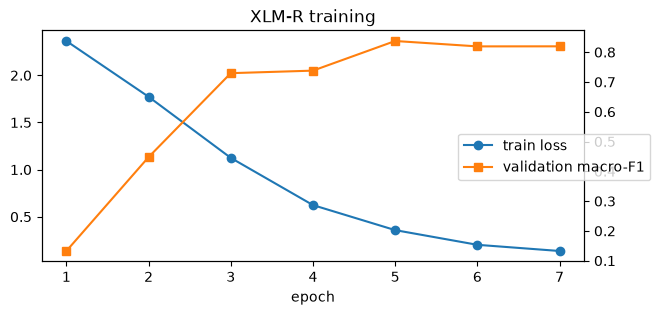

In [8]:
if history:
    h = pd.DataFrame(history)
    fig, ax = plt.subplots(figsize=(7, 3))
    ax.plot(h.epoch, h.train_loss, "o-", label="train loss"); ax2 = ax.twinx()
    ax2.plot(h.epoch, h.val_macro_f1, "s-", c="C1", label="validation macro-F1")
    ax.set_xlabel("epoch"); ax.set_title("XLM-R training"); fig.legend(loc="center right"); plt.show()

## Choose the threshold on validation

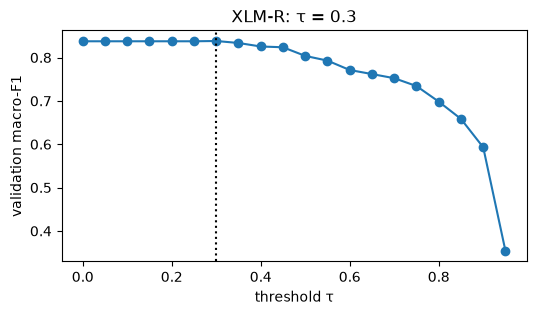

In [9]:
xl_va = predict_proba(model, va.text.tolist())
TAU, tau_scores = choose_threshold(xl_va, y_va)
plt.figure(figsize=(6, 3)); plt.plot(np.round(np.arange(0.0, 0.951, 0.05), 2), tau_scores, "o-")
plt.axvline(TAU, c="k", ls=":"); plt.xlabel("threshold τ"); plt.ylabel("validation macro-F1"); plt.title(f"XLM-R: τ = {TAU}"); plt.show()

## Test set (used once)

In [10]:
xl_te = predict_proba(model, te.text.tolist())
pred_xl, pred_bl = apply_threshold(xl_te, TAU), apply_threshold(bl_te, BL_TAU)
res = {"xlmr": evaluate(te, y_te, pred_xl), "baseline": evaluate(te, y_te, pred_bl)}
rows = []
for m in ("baseline", "xlmr"):
    for lang, r in res[m].items():
        rows.append({"model": m, "questions": lang, "n": r["n"], "accuracy": r["accuracy"], "macro_F1": r["macro_f1"],
                     "OOS precision": r["oos_precision"], "OOS recall": r["oos_recall"]})
summary = pd.DataFrame(rows)
summary

,model,questions,n,accuracy,macro_F1,OOS precision,OOS recall
0,baseline,all,363,0.7713,0.7220,0.5301,0.8800
1,baseline,en,180,0.7722,0.7280,0.5641,0.8462
2,baseline,si,180,0.7833,0.7296,0.5116,0.9167
3,baseline,si_latn,3,0.0000,0.0000,0.0000,0.0000
4,xlmr,all,363,0.8264,0.7834,0.8222,0.7400
5,xlmr,en,180,0.8667,0.8370,0.9474,0.6923
6,xlmr,si,180,0.8000,0.7268,0.7600,0.7917
7,xlmr,si_latn,3,0.0000,0.0000,0.0000,0.0000


In [11]:
per_intent = pd.DataFrame({f"{m} {lang}": res[m][lang]["per_intent_f1"] for m in ("baseline", "xlmr") for lang in ("en", "si")})
per_intent.round(3)

,baseline en,baseline si,xlmr en,xlmr si
crop_choice,0.951,0.949,0.967,0.949
crop_establishment,0.500,0.710,0.774,0.611
deficiency_symptom,0.667,0.857,0.769,0.706
fertilizer_amount,1.000,0.943,1.000,0.958
fertilizer_timing,0.941,0.833,1.000,0.917
greeting_help,0.667,0.800,1.000,0.952
liming_ph,0.875,0.546,0.875,0.857
my_field_status,0.889,0.818,1.000,0.917
out_of_scope,0.677,0.657,0.800,0.776
pest_disease,0.526,0.500,0.720,0.357


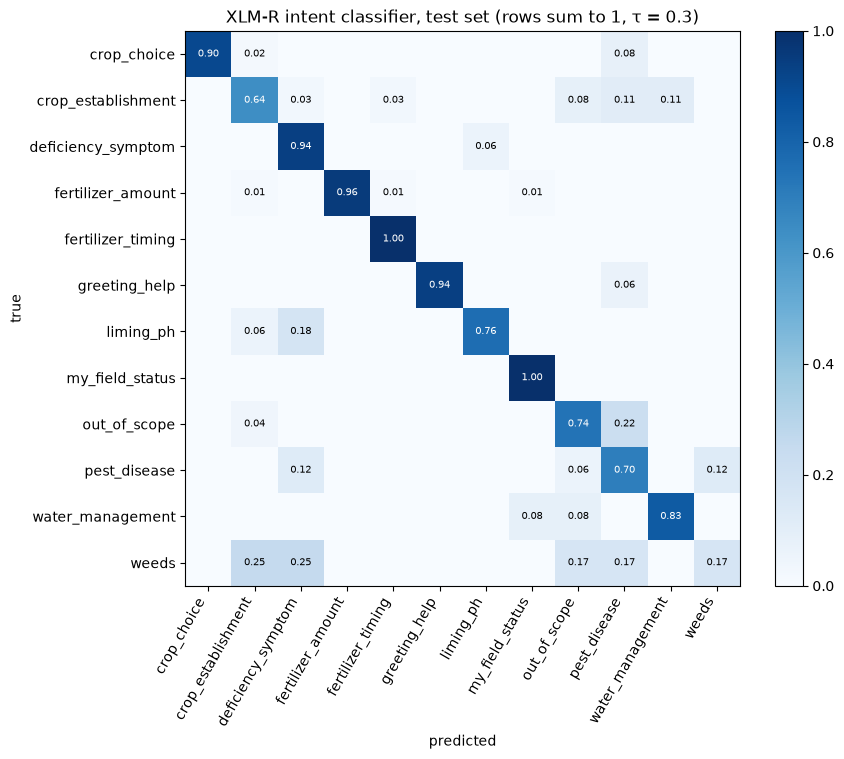

In [12]:
cm = confusion_matrix(y_te, pred_xl, labels=range(len(LABELS)), normalize="true")
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(LABELS)), LABELS, rotation=60, ha="right"); ax.set_yticks(range(len(LABELS)), LABELS)
for i in range(len(LABELS)):
    for j in range(len(LABELS)):
        if cm[i, j] >= 0.01:
            ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", fontsize=7, color="white" if cm[i, j] > 0.5 else "black")
ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(f"XLM-R intent classifier, test set (rows sum to 1, τ = {TAU})")
fig.colorbar(im); plt.tight_layout()
if RETRAIN:
    OUT.mkdir(parents=True, exist_ok=True); fig.savefig(OUT / "confusion_matrix.png", dpi=120)
plt.show()

Some test mistakes, to see what the model confuses:

In [13]:
err = te.assign(pred=[LABELS[p] for p in pred_xl], conf=xl_te.max(1).round(2))
err[err.pred != err.intent][["lang", "text", "intent", "pred", "conf"]].head(15)

,lang,text,intent,pred,conf
123,en,Why are my grains empty or half filled?,pest_disease,deficiency_symptom,0.84
134,en,My leaves are turning brown and seedlings are ...,pest_disease,deficiency_symptom,0.90
135,en,What is barnyard grass and why is it a problem?,weeds,deficiency_symptom,0.47
136,en,How do I control bajiri?,weeds,out_of_scope,0.58
137,en,How quickly does barnyard grass set seed?,weeds,crop_establishment,0.95
143,en,How much water for primary tillage?,crop_establishment,water_management,0.93
144,en,How do I control Atawara and Kaladuru?,crop_establishment,pest_disease,0.90
157,si,මාස 4 වී වලට අන්තිම යූරියා පොහොර දාන්නේ කීවෙනි...,fertilizer_amount,fertilizer_timing,0.94
158,si,පොහොර දාන සති ගණන් කරන්නේ කවදා ඉඳලද?,fertilizer_amount,crop_establishment,0.38
162,si,අනුරාධපුර දිස්ත්‍රික්කයට අදාළ පොහොර නිර්දේශය ක...,fertilizer_amount,my_field_status,0.40


## CPU inference speed
One question at a time on the CPU (the way the chat endpoint will call it).

In [14]:
cpu_model = model.to("cpu").eval()
sample = te.text.sample(100, random_state=SEED).tolist()
times = []
with torch.inference_mode():
    for q in sample:
        t0 = time.perf_counter()
        cpu_model(**tok([q], truncation=True, max_length=MAX_LEN, return_tensors="pt"))
        times.append((time.perf_counter() - t0) * 1000)
LATENCY = {"median_ms": round(float(np.median(times)), 1), "p95_ms": round(float(np.percentile(times, 95)), 1), "threads": torch.get_num_threads()}
print("CPU latency per question:", LATENCY)

CPU latency per question: {'median_ms': 29.3, 'p95_ms': 49.2, 'threads': 16}


## Save the model, threshold, metrics and model card

In [15]:
metrics = {
    "model": MODEL_NAME, "seed": SEED, "labels": LABELS,
    "data": {"train": len(tr), "val": len(va), "test": len(te)},
    "baseline": {"C": float(BEST_C), "threshold": BL_TAU, "test": res["baseline"]},
    "xlmr": {"threshold": TAU, "best_epoch": best_epoch, "history": history, "train_seconds": round(TRAIN_SECONDS),
             "trained_on": DEVICE if RETRAIN else json.loads((OUT / "metrics.json").read_text())["xlmr"]["trained_on"],
             "hyperparameters": {"max_len": MAX_LEN, "batch": BATCH, "lr": LR, "max_epochs": EPOCHS, "patience": PATIENCE,
                                 "warmup": WARMUP, "weight_decay": WEIGHT_DECAY},
             "test": res["xlmr"], "cpu_latency": LATENCY},
}
if RETRAIN:
    OUT.mkdir(parents=True, exist_ok=True)
    model.save_pretrained(OUT / "model"); tok.save_pretrained(OUT / "model")
    joblib.dump(baseline, OUT / "baseline_tfidf_logreg.joblib")
    (OUT / "inference.json").write_text(json.dumps({"labels": LABELS, "threshold": TAU, "max_length": MAX_LEN, "base_model": MODEL_NAME}, indent=2))
    (OUT / "metrics.json").write_text(json.dumps(metrics, indent=2, ensure_ascii=False))
    x, b = res["xlmr"], res["baseline"]
    card = f'''# Model card: SoilMind intent classifier

**What it does.** Sorts a farmer's question (English, Sinhala or Singlish) into one of {len(LABELS)} intents:
{", ".join(LABELS)}. If the top probability is below **τ = {TAU}** the question is treated as `out_of_scope`.

**Model.** `{MODEL_NAME}` (Conneau et al., 2020; 100 languages incl. Sinhala) fine-tuned with a classification
head. Max {MAX_LEN} tokens, batch {BATCH}, lr {LR}, AdamW + linear warm-up, best of up to {EPOCHS} epochs by
validation macro-F1 (best epoch {best_epoch}). Seed {SEED}.

**Training data is NOT human-checked.** All training and test questions were generated by code (templates, paraphrases), drafted by the AI coding assistant (Claude Code), or machine-translated with NLLB-200 (`data/training/DATASET.md`). No team member wrote or checked them, so the scores below measure performance on AI-drafted / machine-translated questions, not on real farmer questions. The human-reviewed check is the end-to-end evaluation set (`eval/qa_testset.xlsx`, notebook 04).

**Data.** `data/training/intents.csv`: {len(tr)} train / {len(va)} validation / {len(te)} test questions, split by
passage group. About half are Sinhala; much of the Sinhala is machine-translated (NLLB) and none of it is human-checked
yet (see DATASET.md).

**Test results** (threshold chosen on validation only):

| Questions | n | Accuracy | Macro-F1 | OOS precision | OOS recall | Baseline macro-F1 |
|---|---|---|---|---|---|---|
''' + "\n".join(f"| {k} | {x[k]['n']} | {x[k]['accuracy']} | {x[k]['macro_f1']} | {x[k]['oos_precision']} | {x[k]['oos_recall']} | {b[k]['macro_f1']} |" for k in x) + f'''

Baseline: TF-IDF (word 1-2 + char 2-5 grams) + logistic regression, C = {BEST_C}, τ = {BL_TAU}.

**Speed.** Trained in {TRAIN_SECONDS / 60:.1f} min on {DEVICE}. CPU inference: median {LATENCY['median_ms']} ms,
p95 {LATENCY['p95_ms']} ms per question ({LATENCY['threads']} threads).

**Limits.** Trained on a small, partly template-generated and machine-translated dataset; real farmer phrasing
(dialect, spelling, code-mixing) will be harder. Intents with few real passages (deficiency, liming) depend on
hand-drafted examples. The threshold trades OOS recall against wrongly refusing in-scope questions.

**Files.** `model/` (weights + tokenizer), `inference.json` (labels, τ), `baseline_tfidf_logreg.joblib`,
`metrics.json`, `confusion_matrix.png`. Loaded by `member4_chatbot.models.predict_intent`.
'''
    (OUT / "model_card.md").write_text(card, encoding="utf-8")
    print("saved to", OUT.resolve())

saved to E:\soilmind\backend\member4-chatbot\artifacts\intent


## Check: does the fine-tuned model beat the baseline?

In [16]:
for lang in ("all", "en", "si"):
    print(f"{lang:>4}: XLM-R macro-F1 {res['xlmr'][lang]['macro_f1']:.4f} vs baseline {res['baseline'][lang]['macro_f1']:.4f}")
assert res["xlmr"]["all"]["macro_f1"] > res["baseline"]["all"]["macro_f1"], "XLM-R does not beat the TF-IDF baseline"
print("XLM-R beats the baseline on the test set.")

 all: XLM-R macro-F1 0.7834 vs baseline 0.7220
  en: XLM-R macro-F1 0.8370 vs baseline 0.7280
  si: XLM-R macro-F1 0.7268 vs baseline 0.7296
XLM-R beats the baseline on the test set.
